# 指示だけの影響と、手がかり追加の影響を分けて見る

PhiでProbeを新しく学習します。学習90文、5指示×19手がかり×3組=285診断行。重複入力を除き361回のforward。回答は生成しません。

**T4 GPUで「すべてのセルを実行」**。Probeの識別確認を先に報告し、主層31・回答開始直前のスコアを図にします。主Probeの確認が通らない組の変化は、概念の変化と解釈しません。これは探索的診断であり、モデル採用判定ではありません。

最終セルでGitHubのmainへ結果・図・Probe重み・特徴を保存します。トークンはColabシークレットから読みます。未完了や保存失敗の場合はZIPを保管できます。モデル再実行なしで検算可能です。


In [1]:
%pip -q uninstall -y torchaudio torchvision
%pip -q install transformers==4.57.6 accelerate scikit-learn scipy pandas numpy sentencepiece requests matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
timm 1.0.30 requires torchvision, which is not installed.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import sys, subprocess, json, hashlib, torch
assert torch.cuda.is_available(), 'T4 GPUが必要です。ランタイム設定を確認してください。'
print('GPU:',torch.cuda.get_device_name(0))
REPO=Path('/content/GraduationThesis-instruction-probe')
if not (REPO/'.git').exists():
    subprocess.run(['git','clone','--depth','1','https://github.com/ryouy/GraduationThesis.git',str(REPO)],check=True)
else:
    subprocess.run(['git','pull','--ff-only'],cwd=REPO,check=True)
FOLDER=REPO/'experiments/2026-11/1104_instruction_probe'
for name,digest in json.loads((FOLDER/'FROZEN_SHA256.json').read_text()).items():
    assert hashlib.sha256((FOLDER/name).read_bytes()).hexdigest()==digest,name
subprocess.run([sys.executable,str(FOLDER/'check.py')],cwd=REPO,check=True)
sys.path.insert(0,str(FOLDER))
from github_save import check_access, save_results, GitHubSaveError
SECRET_NAME='GITHUB_TOKEN' # 秘密値ではなくシークレットのキー名
check_access(SECRET_NAME)
OUT=Path('/content')/('instruction-probe-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
print('Output:',OUT)


GPU: Tesla T4
GitHub接続確認済み（書込みは実験後の保存時に確認）。トークンは表示しません。
Output: /content/instruction-probe-20261104T024551489146Z


In [3]:
# Phiで361入力の内部特徴を抽出。生成・採点は行いません。
subprocess.run([sys.executable,'-u',str(FOLDER/'extract.py'),'--out',str(OUT)],cwd=REPO,check=True)


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/GraduationThesis-instruction-probe/experiments/2026-11/1104_instruction_probe/extract.py', '--out', '/content/instruction-probe-20261104T024551489146Z'], returncode=0)

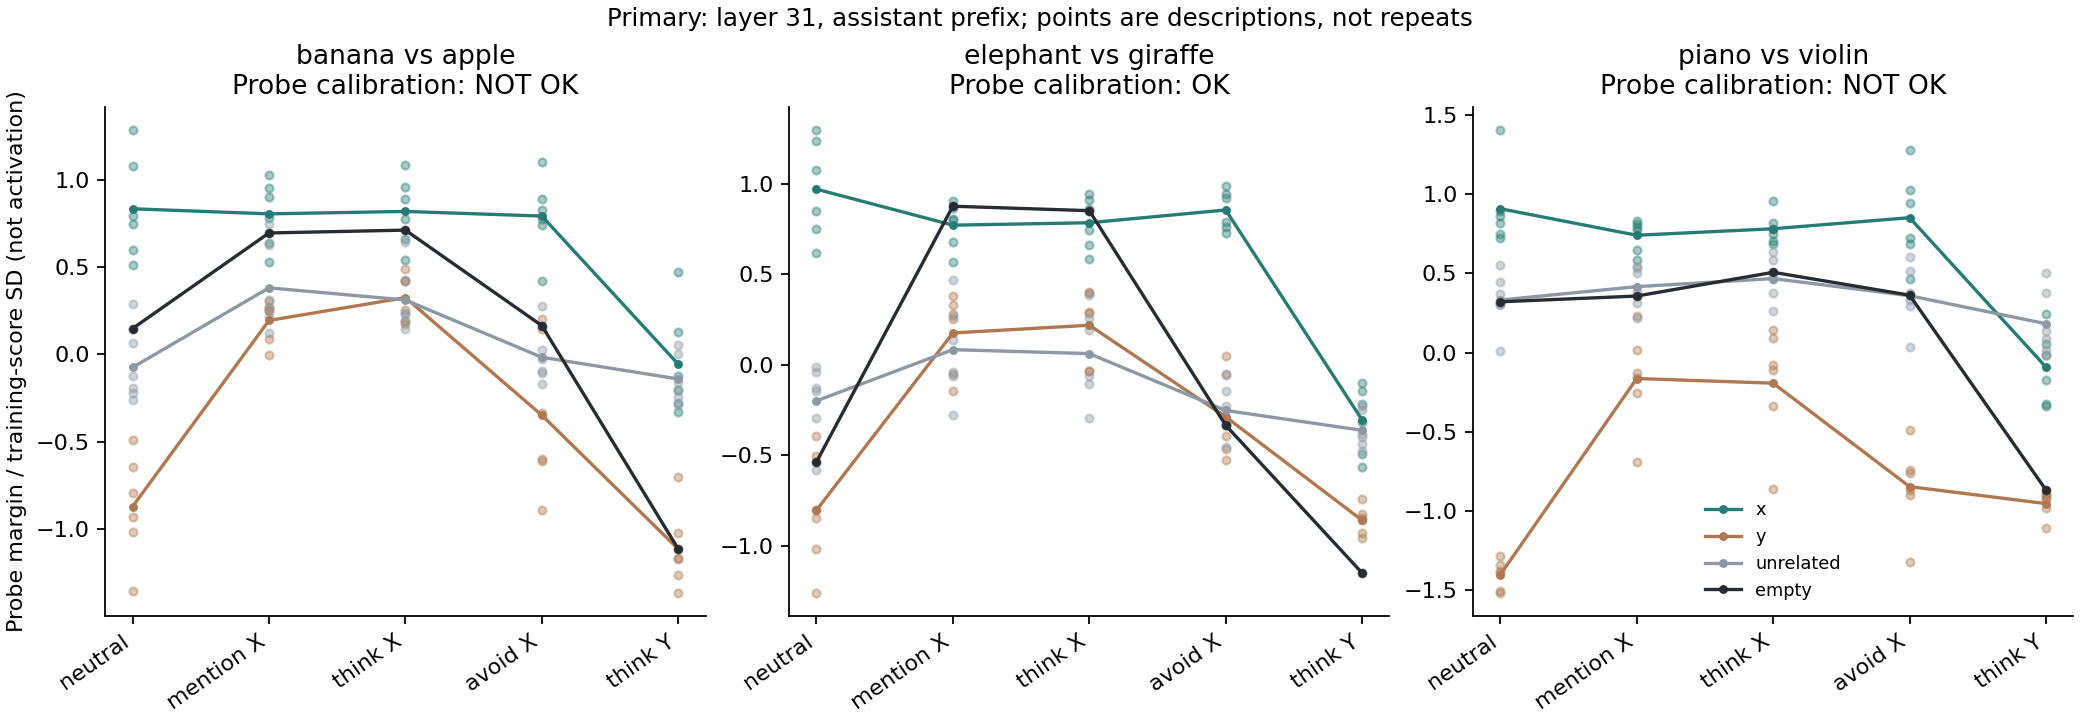

calibration NOT OKの組は、内部スコアを概念変化の証拠として解釈しません。


In [4]:
# CPUでProbeを学習し、ラベルシャッフル対照と指示・手がかりの差を計算。
subprocess.run([sys.executable,'-u',str(FOLDER/'analyze.py'),'--out',str(OUT)],cwd=REPO,check=True)
subprocess.run([sys.executable,str(FOLDER/'make_checksums.py'),str(OUT)],cwd=REPO,check=True)
from IPython.display import display, Image
display(Image(filename=str(OUT/'comparison.png')))
print('calibration NOT OKの組は、内部スコアを概念変化の証拠として解釈しません。')


In [5]:
# 最後：検算済み結果をmainへ自動保存し、ZIPもダウンロード。
# 保存だけ失敗した場合、このセルだけ再実行できます。
import shutil
from google.colab import files
try:
    receipt=save_results(OUT,SECRET_NAME)
    print('GitHub保存確認済み:',receipt['url'])
except GitHubSaveError as exc:
    print(str(exc));print('自動保存は未完了です。ZIPを保管して、この保存セルだけ再実行してください。')
except Exception as exc:
    print('保存前の検算に失敗しました。結果を保管してください。エラー種別:',type(exc).__name__)
finally:
    if OUT.exists():
        archive=shutil.make_archive(str(OUT),'zip',root_dir=OUT)
        files.download(archive)


Verification PASS: 361 inputs, 24 probes, 2280 scores/contrasts, 120 AUCs, 300 label shuffles and 480 aggregates.
GitHub保存確認済み: https://github.com/ryouy/GraduationThesis/tree/387fe53faa1ef6d074bc71ade17a2cea59ab7f64/experiments/2026-11/1104_instruction_probe/results/instruction-probe-20261104T024551489146Z


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>